# State and Day/Night Comparisons — US Accidents Dataset

**Axis 5 — Do the State and the time of day matter?**


---


## 0. Imports and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from scipy.linalg import inv

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
rng = np.random.default_rng(42)


In [ ]:
from pathlib import Path

DATA_DIR = Path("D:/Accidents_USA/Dataset")   
DATA_PATH = DATA_DIR / "US_Accidents_Sample500k_Clean.csv"   

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")


Shape: 500,000 rows x 32 columns


In [3]:
top_states = df['State'].value_counts().head(8).index.tolist()
print("States compared:", top_states)


States compared: ['CA', 'TX', 'FL', 'SC', 'PA', 'NY', 'IL', 'NC']


---
## 1. Kruskal-Wallis test — Severity by State



H = 15723.19, p-value = 0, epsilon squared = 0.0485


,mean,median,count
State,,,
IL,2.454,2.0,20451
NY,2.425,2.0,20871
CA,2.375,2.0,114346
TX,2.296,2.0,55102
FL,2.274,2.0,47947
PA,2.199,2.0,21976
NC,2.091,2.0,17036
SC,2.042,2.0,26607


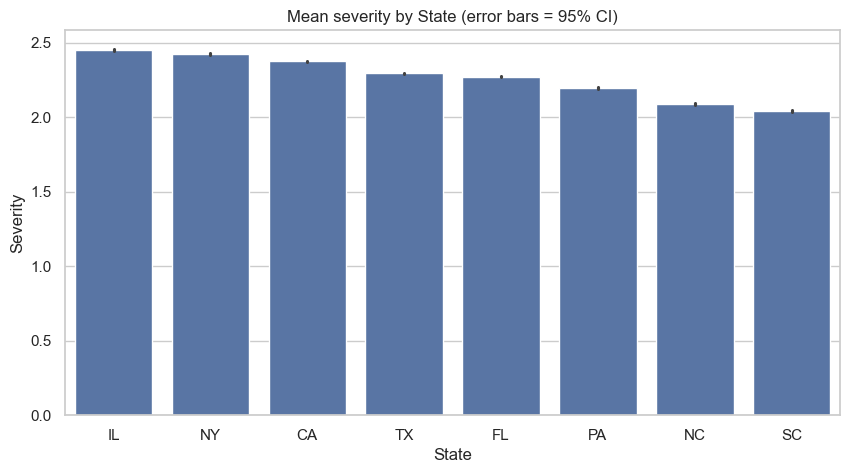

In [ ]:
state_df = df[df['State'].isin(top_states)]
groups = [state_df.loc[state_df['State'] == s, 'Severity'] for s in top_states]

h_stat, p_value = stats.kruskal(*groups)
epsilon2 = h_stat / (len(state_df) - 1)  
print(f"H = {h_stat:.2f}, p-value = {p_value:.4g}, epsilon squared = {epsilon2:.4f}")

display(state_df.groupby('State')['Severity'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False).round(3))

plt.figure(figsize=(10, 5))
sns.barplot(x='State', y='Severity', data=state_df, order=state_df.groupby('State')['Severity'].mean().sort_values(ascending=False).index)
plt.title("Mean severity by State (error bars = 95% CI)")
plt.show()


---
## 2. Chi-square test — Day/Night vs Severity

In [5]:
dn = df.dropna(subset=['Sunrise_Sunset'])
contingency = pd.crosstab(dn['Sunrise_Sunset'], dn['Severity'])
chi2, p_value, dof, expected = chi2_contingency(contingency)
v = np.sqrt(chi2 / (contingency.to_numpy().sum() * (min(contingency.shape) - 1)))
print(f"Chi2 = {chi2:.2f}, dof = {dof}, p-value = {p_value:.4g}, Cramer's V = {v:.4f}")

(pd.crosstab(dn['Sunrise_Sunset'], dn['Severity'], normalize='index') * 100).round(1)


Chi2 = 584.99, dof = 3, p-value = 1.81e-126, Cramer's V = 0.0342


Severity,1,2,3,4
Sunrise_Sunset,,,,
Day,3.1,62.4,34.1,0.5
Night,1.9,62.6,34.7,0.7


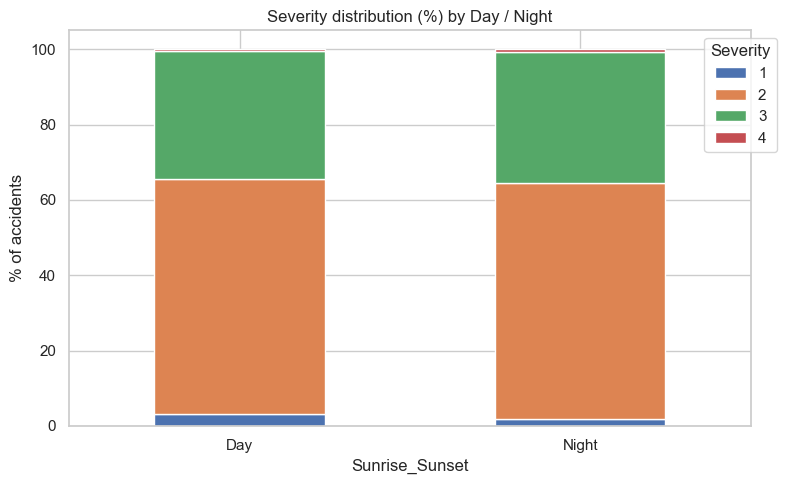

In [6]:
pct = pd.crosstab(dn['Sunrise_Sunset'], dn['Severity'], normalize='index') * 100
pct.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title("Severity distribution (%) by Day / Night")
plt.ylabel("% of accidents")
plt.xticks(rotation=0)
plt.legend(title='Severity', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


---
## 3. Bootstrap confidence interval — mean severity difference between two States



Observed difference of means (CA - TX): 0.0873
95% bootstrap CI: [0.0732, 0.1015]


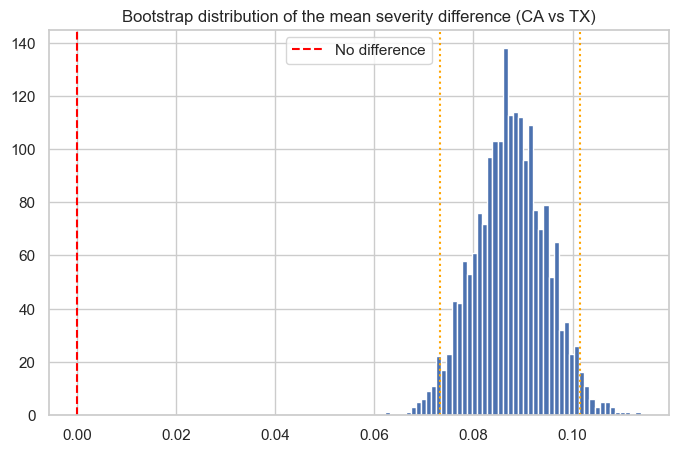

In [7]:
state_a, state_b = top_states[0], top_states[1]
a_all = df.loc[df['State'] == state_a, 'Severity'].dropna().to_numpy()
b_all = df.loc[df['State'] == state_b, 'Severity'].dropna().to_numpy()

n_sub = min(10_000, len(a_all), len(b_all))
a = rng.choice(a_all, size=n_sub, replace=False)
b = rng.choice(b_all, size=n_sub, replace=False)

n_boot = 2000
boot_diffs = np.empty(n_boot)
for i in range(n_boot):
    boot_diffs[i] = rng.choice(a, size=n_sub, replace=True).mean() - rng.choice(b, size=n_sub, replace=True).mean()

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
print(f"Observed difference of means ({state_a} - {state_b}): {a.mean() - b.mean():.4f}")
print(f"95% bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]")

plt.figure(figsize=(8, 5))
plt.hist(boot_diffs, bins=50)
plt.axvline(0, color='red', linestyle='--', label='No difference')
plt.axvline(ci_low, color='orange', linestyle=':')
plt.axvline(ci_high, color='orange', linestyle=':')
plt.title(f"Bootstrap distribution of the mean severity difference ({state_a} vs {state_b})")
plt.legend()
plt.show()


---
## 4. Hotelling's T² — Severity and Distance(mi) jointly, day vs night




In [ ]:
def hotelling_t2(g1, g2):
    n1, n2, p = len(g1), len(g2), g1.shape[1]
    diff = g1.mean(axis=0) - g2.mean(axis=0)
    pooled = ((n1 - 1) * np.cov(g1, rowvar=False) + (n2 - 1) * np.cov(g2, rowvar=False)) / (n1 + n2 - 2)
    d2 = float(diff @ inv(pooled) @ diff)                 
    t2 = (n1 * n2) / (n1 + n2) * d2
    f_stat = t2 * (n1 + n2 - p - 1) / (p * (n1 + n2 - 2))
    p_value = stats.f.sf(f_stat, p, n1 + n2 - p - 1)
    return t2, f_stat, p_value, np.sqrt(d2)

cols = ['Severity', 'Distance(mi)']
hot = df.dropna(subset=cols + ['Sunrise_Sunset'])
day = hot.loc[hot['Sunrise_Sunset'] == 'Day', cols].to_numpy()
night = hot.loc[hot['Sunrise_Sunset'] == 'Night', cols].to_numpy()

t2, f_stat, p_value, mahal = hotelling_t2(day, night)
print(f"Hotelling T2 = {t2:.2f}, F = {f_stat:.2f}, p-value = {p_value:.4g}")
print(f"Mahalanobis distance = {mahal:.3f} standard deviations")
print(f"Group sizes: day = {len(day):,}, night = {len(night):,}")


Hotelling T2 = 181.22, F = 90.61, p-value = 4.53e-40
Mahalanobis distance = 0.043 standard deviations
Group sizes: day = 360,799, night = 138,609
